# Mini-Project 2: Uganda Tax Engine

**Course:** MSCS & MSDS OOP with Python, Assignment 2 (Advent 2026)

An extensible, testable calculator for taxes administered by the Uganda Revenue Authority (URA): **PAYE**
(resident and non-resident), **NSSF**, **Local Service Tax**, a **payroll pipeline**, **VAT** and **corporate income
tax**. The extension is **B: a `TaxPlanner`** comparing salary and dividend extraction.

All logic lives in the package `src/uganda_tax/`; this notebook demonstrates it.

## Design overview

```
                    ┌──────────────────────────┐
                    │  Tax (ABC)               │  calculate(self, ctx: TaxContext) -> TaxResult
                    │  + _result(): rounds once│
                    └────────────┬─────────────┘
       ┌──────────┬──────────────┼──────────────┬──────────────┬─────────────────────────┐
     PAYE        NSSF      LocalServiceTax      VAT    CorporateIncomeTax   DividendWithholdingTax
       │ has-a                  │ has-a
 ScheduleRegistry[ProgressiveSchedule]   ScheduleRegistry[StepSchedule]     (rates are data, chosen by date)
       │ has-many
     Band(lower, upper, rate)

 PayrollPipeline  ──composes──►  NSSF → LST → PAYE            ──► Payslip
 TaxPlanner       ──composes──►  Scenario (ABC): SalaryScenario (uses PayrollPipeline + CIT)
                                                 DividendScenario (uses CIT + WHT)        ──► Comparison
 Money (Decimal value object, UGX)      TaxContext (input)      TaxResult / ResultLine (output)
 TaxError ─┬─ InvalidIncomeError   ─ NoScheduleForDateError   ─ CurrencyMismatchError
           └─ ScheduleConfigurationError   ─ InvalidSupplyError
```

| Module | Responsibility |
|---|---|
| `money.py` | `Money`: immutable `Decimal` amount in UGX; rejects `float`; explicit rounding; operator overloading |
| `exceptions.py` | `TaxError` hierarchy |
| `context.py` | `TaxContext` (input facts), `TaxResult`/`ResultLine` (output), `Invoice`, `Deduction`, enums |
| `base.py` | Abstract `Tax` with `calculate(ctx) -> TaxResult` |
| `schedules.py` | `Band`, `ProgressiveSchedule`, `StepSchedule`, dated `ScheduleRegistry` |
| `rates.py` | All statutory rates with sources and effective dates |
| `paye.py`, `nssf.py`, `lst.py`, `vat.py`, `cit.py` | One class per tax |
| `payroll.py` | `PayrollPipeline` and `Payslip` |
| `planner.py` | Extension B: `TaxPlanner`, `Scenario`s, `Comparison` |
| `plots.py` | Charts (the only place where `Money` is converted to `float`, for drawing) |

## Regulatory baseline and sources

The brief asks for rates to be confirmed against URA documentation. They were checked on **16 October 2026**:

| Tax | Rule implemented | Source / version |
|---|---|---|
| PAYE resident, **FY 2026/27** (from 1 Jul 2026) | Nil to 335,000; 20% to 410,000; 15,000 + 25% to 485,000; 33,750 + 30% above; +10% above 10,000,000 | URA *PAYE rates* page (ura.go.ug/?p=16453), Income Tax (Amendment) Act 2026. **Identical to the brief.** |
| PAYE resident, **FY 2025/26** (to 30 Jun 2026) | Nil to 235,000; 10% to 335,000; 10,000 + 20% to 410,000; 25,000 + 30% above; +10% above 10,000,000 | Schedule replaced by the 2026 amendment (kept so that back-pay is computed with the rates of its own month) |
| PAYE non-resident | 10% to 335,000; 33,500 + 20% to 410,000; 48,500 + 30% above; +10% above 10,000,000 | URA *PAYE rates* page |
| NSSF | Employee 5%, employer 10% of gross emoluments | NSSF Act |
| Local Service Tax | UGX 5,000–100,000 a year in ten bands by monthly gross income, collected July–October, deducted before PAYE | Local Governments (Amendment) (No. 2) Act 2008; table and the "deduct before PAYE" rule from KCCA's *LST (Assessment & Payment)* FAQ, Feb 2017 |
| VAT | 18% standard; zero-rated; exempt | VAT Act |
| Corporate income tax | 30% of chargeable income (resident companies) | Income Tax Act |
| Withholding tax on dividends (planner) | 15% (unlisted company paying a resident) | Income Tax Act; PwC Worldwide Tax Summaries, Uganda, reviewed Jan 2026 |

Dates outside the modelled periods raise `NoScheduleForDateError` rather than silently using the wrong year's rates.

**Libraries beyond the core list**, with a one-line justification each: `decimal` (required by the brief for money);
`hypothesis` (required for property-based tests); `numpy` (seeded `default_rng`, as required); `abc`, `dataclasses`,
`enum`, `functools` and `typing` (standard-library OOP building blocks: abstract base classes, value objects,
enumerations, `total_ordering` and type hints); `subprocess` and `sys` (run the test suite from the notebook);
`IPython.display` and `jinja2` (show formatted tables).

In [1]:
import datetime as dt
import subprocess
import sys
from decimal import ROUND_HALF_EVEN, Decimal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from uganda_tax import (
    NSSF, PAYE, VAT, CorporateIncomeTax, CurrencyMismatchError, Deduction, InvalidIncomeError,
    InvalidSupplyError, Invoice, InvoiceDirection, LocalServiceTax, Money, NoScheduleForDateError,
    PayrollPipeline, Residency, SupplyType, TaxContext, TaxError, TaxPlanner,
)
from uganda_tax.plots import plot_paye_schedules, plot_payroll, plot_planner
from uganda_tax.rates import PAYE_NON_RESIDENT, PAYE_RESIDENT_FY2025, PAYE_RESIDENT_FY2026
from uganda_tax.tables import results_table

SEED = 2026
rng = np.random.default_rng(SEED)      # reproducible sample payroll below
pd.set_option("display.width", 140)

AUG_2026 = dt.date(2026, 8, 31)        # a month in FY 2026/27 inside the LST collection window
MAR_2026 = dt.date(2026, 3, 31)        # a month in FY 2025/26

---
## 1. Money handling with `Decimal`

`Money` wraps a `Decimal`. It is a frozen dataclass, so it is immutable and hashable, and it overloads `+ - * /`,
comparisons (`__lt__` plus `functools.total_ordering`), `__repr__` and `__str__`.

**Rounding rule.** Arithmetic keeps full precision. Each tax rounds its *final* liability **once**, to the
**whole shilling, half-up** (`ROUND_HALF_UP`), in `Tax._result()`. VAT is rounded per invoice, as it would be
printed on each invoice.

In [2]:
salary = Money(1_250_000)
allowance = Money("85000.50")
print(repr(salary + allowance), "|", salary + allowance)
print("x 0.30          :", repr(salary * Decimal("0.30")))
print("comparison      :", allowance < salary, max(salary, allowance))
print("half-up rounding:", Money("2.5").rounded(), "vs banker's:", Money("2.5").rounded(rounding=ROUND_HALF_EVEN))

for bad in (lambda: Money(0.1), lambda: salary * 0.18, lambda: Money(1, "UGX") + Money(1, "USD"), lambda: Money("abc")):
    try:
        bad()
    except (TypeError, TaxError) as exc:
        print(f"refused -> {type(exc).__name__}: {exc}")

Money('1335000.50', 'UGX') | UGX 1,335,001
x 0.30          : Money('375000.00', 'UGX')
comparison      : True UGX 1,250,000
half-up rounding: UGX 3 vs banker's: UGX 2
refused -> TypeError: float is not allowed for money; use Decimal, int or str
refused -> TypeError: float is not allowed for money; use Decimal, int or str
refused -> CurrencyMismatchError: Cannot combine UGX with USD
refused -> InvalidIncomeError: Not a valid number: 'abc'


### Discussion Q1: Why is `float` unsafe for tax computation?

A binary `float` cannot represent most decimal fractions exactly: `0.1` is stored as
`0.1000000000000000055511151231257827…`. The errors are tiny, but tax rules turn on **exact comparisons at band
edges** and on **rounding at exact halves**, and those are where tiny errors become wrong answers.

In [3]:
# (a) Classic accumulation error
total = 0.0
for _ in range(10):
    total += 0.1
print("float: 0.1 added ten times =", repr(total), "| == 1.0?", total == 1.0)
print("Money: 0.1 added ten times =", Money.sum([Money("0.1")] * 10))

float: 0.1 added ten times = 0.9999999999999999 | == 1.0? False
Money: 0.1 added ten times = UGX 1


In [4]:
# (b) A failing tax example: an employee's pay is made up of three components that sum to EXACTLY 335,000,
#     the top of the nil band. With float the sum lands just above the edge, so the employee falls into the 20% band.
parts = ["100000.10", "200000.20", "34999.70"]
float_income = 0.0
for p in parts:
    float_income += float(p)
decimal_income = Money.sum(Money(p) for p in parts)

def float_paye(income: float) -> float:
    "A naive float implementation of the FY 2026/27 resident schedule (first two bands are enough here)."
    if income <= 335_000:
        return 0.0
    return 0.20 * (min(income, 410_000) - 335_000)

print("\nfloat income   :", repr(float_income), "> 335,000?", float_income > 335_000)
print("float PAYE     :", repr(float_paye(float_income)), " <- tax charged on income that is not taxable")
paye_exact = PAYE().calculate(TaxContext(on=AUG_2026, gross_pay=decimal_income))
print("Decimal income :", repr(decimal_income), "> 335,000?", decimal_income > Money(335_000))
print("Decimal PAYE   :", repr(paye_exact.unrounded), "(nil band, exactly)")


float income   : 335000.00000000006 > 335,000? True
float PAYE     : 1.1641532182693482e-11  <- tax charged on income that is not taxable
Decimal income : Money('335000.00', 'UGX') > 335,000? False
Decimal PAYE   : Money('0', 'UGX') (nil band, exactly)


In [5]:
# (c) Rounding of halves: Python's round() on floats is banker's rounding AND sees the binary value
print("\nround(2.5) =", round(2.5), "(half-even, a shilling lost)")
print("round(2.675, 2) =", round(2.675, 2), "(2.675 is really 2.67499999…, so it rounds down)")
print("Money('2.675').rounded(2) =", repr(Money("2.675").rounded(2)))


round(2.5) = 2 (half-even, a shilling lost)
round(2.675, 2) = 2.67 (2.675 is really 2.67499999…, so it rounds down)
Money('2.675').rounded(2) = Money('2.68', 'UGX')


The `float` version charges tax (and in a real system would set a "taxable" flag, choose a band label, or trigger a
filing obligation) for an employee whose income is exactly at the nil-band limit. The amount is microscopic, but
the *classification* is wrong. Over thousands of payslips and repeated sums, such errors also accumulate into
reconciliation differences against URA's records. `Decimal` represents `100000.10` exactly, so band tests are
exact, and the rounding mode is chosen explicitly instead of inherited from the hardware.

---
## 2. PAYE calculator

`PAYE.calculate(ctx)` picks the schedule from the registry for the context's **residency** and **date**, computes
the chargeable income (`gross pay + allowances − pre-PAYE deductions`), and applies the marginal bands plus the 10%
surcharge above 10,000,000.

In [6]:
paye = PAYE()
ctx = TaxContext(on=AUG_2026, gross_pay=Money(11_500_000), allowances=Money(500_000))
result = paye.calculate(ctx)
print(result, "| effective rate", f"{result.effective_rate:.2%}")
display(results_table([result]))

PAYE: UGX 3,688,250 on base UGX 12,000,000 [PAYE resident FY2026/27] | effective rate 30.74%


,Tax,Line,Base (UGX),Rate,Amount (UGX)
0,PAYE,"Band 0 - 335,000",335000,0%,0
1,PAYE,"Band 335,000 - 410,000",75000,20%,15000.00
2,PAYE,"Band 410,000 - 485,000",75000,25%,18750.00
3,PAYE,"Band 485,000 and above",11515000,30%,3454500.00
4,PAYE,"Surcharge above 10,000,000",2000000,10%,200000.00


### Boundary values (every band edge in the brief)

In [7]:
edges = [335_000, 335_001, 410_000, 410_001, 485_000, 485_001, 10_000_000, 10_000_001]
rows = []
for income in edges:
    row = {"Monthly income (UGX)": income}
    for label, residency, on in [("Resident FY26/27", Residency.RESIDENT, AUG_2026),
                                 ("Resident FY25/26", Residency.RESIDENT, MAR_2026),
                                 ("Non-resident", Residency.NON_RESIDENT, AUG_2026)]:
        r = paye.calculate(TaxContext(on=on, gross_pay=Money(income), residency=residency))
        row[f"{label} exact"] = r.unrounded.amount
        row[f"{label} rounded"] = r.amount.amount
    rows.append(row)
pd.DataFrame(rows).set_index("Monthly income (UGX)")

,Resident FY26/27 exact,Resident FY26/27 rounded,Resident FY25/26 exact,Resident FY25/26 rounded,Non-resident exact,Non-resident rounded
Monthly income (UGX),,,,,,
335000,0,0,10000.00,10000,33500.00,33500
335001,0.20,0,10000.20,10000,33500.20,33500
410000,15000.00,15000,25000.00,25000,48500.00,48500
410001,15000.25,15000,25000.30,25000,48500.30,48500
485000,33750.00,33750,47500.00,47500,71000.00,71000
485001,33750.30,33750,47500.30,47500,71000.30,71000
10000000,2888250.00,2888250,2902000.00,2902000,2925500.00,2925500
10000001,2888250.40,2888250,2902000.40,2902000,2925500.40,2925500


The FY 2026/27 resident column matches the hand calculations in `tests/test_paye.py`, for example
10,000,001 → 33,750 + 30% × 9,515,001 + 10% × 1 = 2,888,250.40 → **2,888,250**.

### Selecting a schedule by date, and failing loudly

In [8]:
for on in (MAR_2026, AUG_2026, dt.date(2024, 1, 31)):
    try:
        r = paye.calculate(TaxContext(on=on, gross_pay=Money(500_000)))
        print(f"{on}: {r.amount}  [{r.schedule}]")
    except NoScheduleForDateError as exc:
        print(f"{on}: {type(exc).__name__}: {exc}")

for bad_ctx in (lambda: TaxContext(on=AUG_2026, gross_pay=Money(-5)),
                lambda: paye.calculate(TaxContext(on=AUG_2026))):
    try:
        bad_ctx()
    except InvalidIncomeError as exc:
        print(f"{type(exc).__name__}: {exc}")

2026-03-31: UGX 52,000  [PAYE resident FY2025/26]
2026-08-31: UGX 38,250  [PAYE resident FY2026/27]
2024-01-31: NoScheduleForDateError: No PAYE (resident) schedule is in force on 2024-01-31: modelled periods are 2025-07-01..2026-06-30, 2026-07-01..open
InvalidIncomeError: gross_pay cannot be negative (UGX -5)
InvalidIncomeError: gross_pay is required for employment taxes


### Visualising the schedules

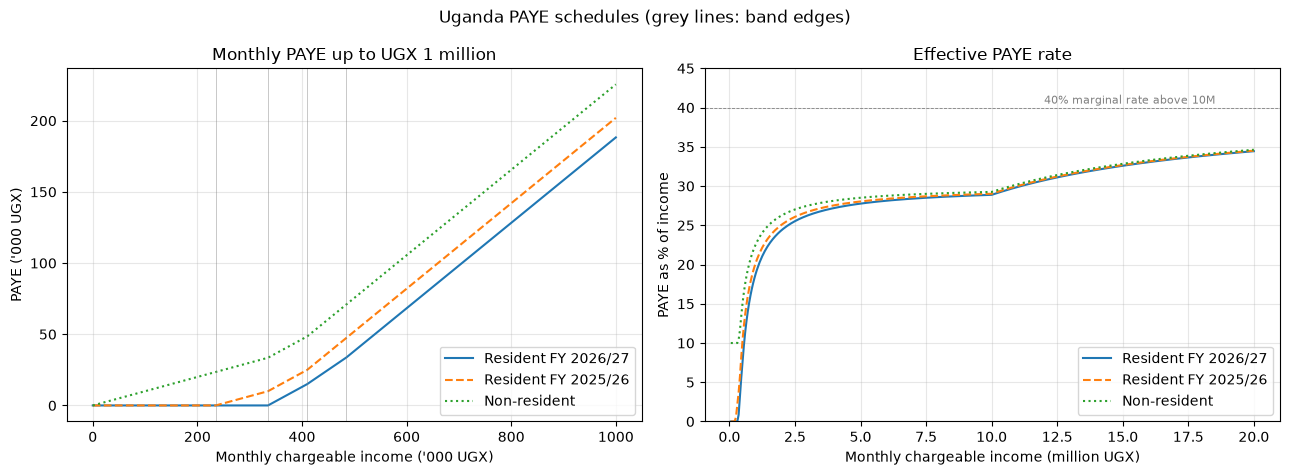

In [9]:
fig = plot_paye_schedules([(PAYE_RESIDENT_FY2026, "Resident FY 2026/27"),
                           (PAYE_RESIDENT_FY2025, "Resident FY 2025/26"),
                           (PAYE_NON_RESIDENT, "Non-resident")])
plt.show()

The FY 2026/27 schedule raises the nil band from 235,000 to 335,000 and adds a 25% band. Every resident earning
more than 235,000 a month pays less PAYE than under FY 2025/26 (the saving reaches 13,750 a month at 485,000 and
stays constant above it, since both schedules then charge 30% at the margin). Non-residents pay from the first shilling, so their effective rate is far higher at low
incomes, but all three curves converge towards 40% at high incomes.

---
## 3. Payroll pipeline: NSSF, Local Service Tax, PAYE and net pay

### Order of deductions and justification

1. **NSSF** (employee 5%, employer 10%) on gross emoluments (gross pay plus allowances). Under the Income Tax Act
   the employee's NSSF contribution is **not deductible** for PAYE, so it does not change the PAYE base. It comes
   first only because it is the statutory social-security deduction and appears first on the payslip.
2. **Local Service Tax** is looked up from monthly income and spread over the July–October instalment months. As
   the brief specifies, it is a deduction **applied before PAYE**, so it must be computed before PAYE.
3. **PAYE** on `emoluments − LST`.
4. **Net pay** = emoluments − employee NSSF − LST − PAYE. The employer's 10% NSSF is a cost to the employer, not a
   deduction from pay.

So the only ordering that changes any amount is **LST before PAYE**. The pipeline encodes it in one place
(`PayrollPipeline.run`), and the pipeline *composes* the three tax objects, so each can be replaced (for example
`LocalServiceTax(enabled=False)` for an exempt employee).

In [10]:
pipeline = PayrollPipeline()
slip = pipeline.run(TaxContext(on=AUG_2026, gross_pay=Money(2_000_000), allowances=Money(300_000)))
print(slip)
display(results_table([slip.nssf, slip.lst, slip.paye]))

Payslip for August 2026 (PAYE resident FY2026/27)
Gross pay                               2,000,000
Allowances                                300,000
Employment income                       2,300,000
Less NSSF (employee 5%)                  -115,000
Less Local Service Tax                    -25,000
Less PAYE                                -570,750
Net pay                                 1,589,250
Employer NSSF (10%, not deducted)         230,000


,Tax,Line,Base (UGX),Rate,Amount (UGX)
0,NSSF,Employee contribution,2300000,5%,115000.00
1,LST,"Instalment (4 per year) of annual UGX 100,000",2300000,1/4 of annual,25000
2,PAYE,"Band 0 - 335,000",335000,0%,0
3,PAYE,"Band 335,000 - 410,000",75000,20%,15000.00
4,PAYE,"Band 410,000 - 485,000",75000,25%,18750.00
5,PAYE,"Band 485,000 and above",1790000,30%,537000.00


In [11]:
# A reproducible sample payroll: 10 employees drawn with a fixed seed, in whole shillings (integers, no floats).
names = [f"Employee {i + 1:02d}" for i in range(10)]
gross = rng.integers(250, 5_000, size=10) * 1_000                      # 250,000 - 4,999,000 UGX
allow = gross * rng.integers(0, 26, size=10) // 100 // 1_000 * 1_000    # 0-25% of gross, whole thousands
residency = [Residency.NON_RESIDENT if r == 0 else Residency.RESIDENT for r in rng.integers(0, 5, size=10)]

slips = pipeline.run_many(
    TaxContext(on=AUG_2026, gross_pay=Money(int(g)), allowances=Money(int(a)), residency=r)
    for g, a, r in zip(gross, allow, residency)
)
payroll = pd.DataFrame([s.as_dict() for s in slips], index=names).drop(columns="Date")
payroll.insert(0, "Residency", [r.value for r in residency])
display(payroll.style.format({c: "{:,.0f}" for c in payroll.columns if c.endswith("(UGX)")}))
print("Total PAYE to remit to URA:", Money.sum(s.paye.amount for s in slips))
print("Total NSSF (employee + employer):", Money.sum(s.nssf.amount + s.nssf_employer for s in slips))

,Residency,Gross pay (UGX),Allowances (UGX),NSSF employee (UGX),LST (UGX),PAYE base (UGX),PAYE (UGX),Net pay (UGX),NSSF employer (UGX),Schedule
Employee 01,non_resident,"4,296,000","902,000","259,900","25,000","5,173,000","1,477,400","3,435,700","519,800",PAYE non-resident FY2025/26 onwards
Employee 02,resident,"1,099,000","219,000","65,900","25,000","1,293,000","276,150","950,950","131,800",PAYE resident FY2026/27
Employee 03,resident,"375,000","67,000","22,100","7,500","434,500","21,125","391,275","44,200",PAYE resident FY2026/27
Employee 04,resident,"3,289,000","756,000","202,250","25,000","4,020,000","1,094,250","2,723,500","404,500",PAYE resident FY2026/27
Employee 05,resident,"1,986,000","357,000","117,150","25,000","2,318,000","583,650","1,617,200","234,300",PAYE resident FY2026/27
Employee 06,resident,"2,469,000","98,000","128,350","25,000","2,542,000","650,850","1,762,800","256,700",PAYE resident FY2026/27
Employee 07,resident,"629,000","138,000","38,350","17,500","749,500","113,100","598,050","76,700",PAYE resident FY2026/27
Employee 08,resident,"2,009,000","321,000","116,500","25,000","2,305,000","579,750","1,608,750","233,000",PAYE resident FY2026/27
Employee 09,non_resident,"3,306,000","66,000","168,600","25,000","3,347,000","929,600","2,248,800","337,200",PAYE non-resident FY2025/26 onwards
Employee 10,resident,"1,935,000","135,000","103,500","25,000","2,045,000","501,750","1,439,750","207,000",PAYE resident FY2026/27


Total PAYE to remit to URA: UGX 6,227,625
Total NSSF (employee + employer): UGX 3,667,800


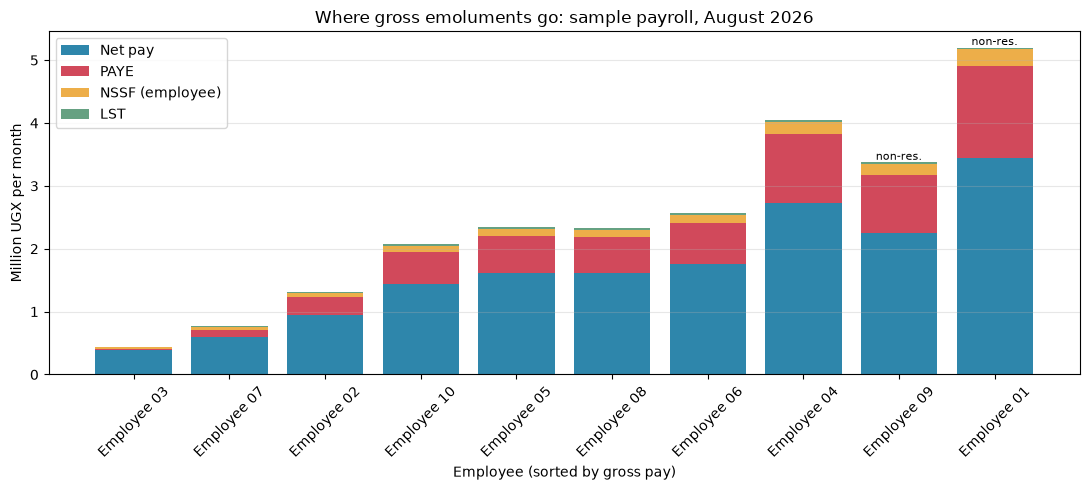

In [12]:
fig = plot_payroll(payroll, "Where gross emoluments go: sample payroll, August 2026")
plt.show()

### A finding: the LST "cliff"

LST is a *step* function of income, and it is deducted before PAYE. When monthly pay crosses an LST band edge,
the monthly LST instalment jumps by a fixed amount, while PAYE falls only by 30% of that jump. So **net pay
can fall when gross pay rises by one shilling**.

In [13]:
rows = []
for g in (999_999, 1_000_000, 1_000_001):
    s = pipeline.run(TaxContext(on=AUG_2026, gross_pay=Money(g)))
    rows.append({"Gross (UGX)": g, "LST (UGX)": s.lst.amount.amount, "PAYE (UGX)": s.paye.amount.amount,
                 "Net pay (UGX)": s.net_pay.amount})
pd.DataFrame(rows).set_index("Gross (UGX)")

,LST (UGX),PAYE (UGX),Net pay (UGX)
Gross (UGX),,,
999999,22500,181500,745999
1000000,22500,181500,746000
1000001,25000,180750,744251


A one-shilling raise from 1,000,000 to 1,000,001 *reduces* August take-home pay by about 1,749 shillings. This is
why the property-based tests assert monotonicity for **PAYE** (which is monotonic) but not for net pay after LST
(which is not). The hypothesis tests for the payroll check `0 ≤ net ≤ income` and the identity
`net + deductions = income` instead.

---
## 4. VAT module

In [14]:
invoices = [
    Invoice("S-001", Money(12_000_000), SupplyType.STANDARD, InvoiceDirection.SALE, "Office furniture"),
    Invoice("S-002", Money(4_500_000), SupplyType.ZERO_RATED, InvoiceDirection.SALE, "Export to Kenya"),
    Invoice("S-003", Money(2_000_000), SupplyType.EXEMPT, InvoiceDirection.SALE, "Unprocessed foodstuffs"),
    Invoice("P-101", Money(6_000_000), SupplyType.STANDARD, InvoiceDirection.PURCHASE, "Timber"),
    Invoice("P-102", Money(850_333), SupplyType.STANDARD, InvoiceDirection.PURCHASE, "Electricity"),
    Invoice("P-103", Money(1_200_000), SupplyType.EXEMPT, InvoiceDirection.PURCHASE, "Medical insurance"),
]
vat = VAT()
vat_result = vat.calculate(TaxContext(on=AUG_2026, invoices=invoices))

table = pd.DataFrame([{
    "Invoice": i.number, "Description": i.description, "Direction": i.direction.value,
    "Supply": i.supply_type.value, "Net (UGX)": i.net_amount.amount, "Rate": f"{vat.rate_for(i.supply_type):.0%}",
    "VAT (UGX)": vat.invoice_vat(i).amount} for i in invoices]).set_index("Invoice")
display(table)
for key in ("output_vat", "input_vat", "net_vat"):
    print(f"{key.replace('_', ' ').title():<10}: {vat_result.notes[key]}")
print("Net VAT payable:", vat_result.amount)

,Description,Direction,Supply,Net (UGX),Rate,VAT (UGX)
Invoice,,,,,,
S-001,Office furniture,sale,standard,12000000,18%,2160000
S-002,Export to Kenya,sale,zero_rated,4500000,0%,0
S-003,Unprocessed foodstuffs,sale,exempt,2000000,0%,0
P-101,Timber,purchase,standard,6000000,18%,1080000
P-102,Electricity,purchase,standard,850333,18%,153060
P-103,Medical insurance,purchase,exempt,1200000,0%,0


Output Vat: UGX 2,160,000
Input Vat : UGX 1,233,060
Net Vat   : UGX 926,940
Net VAT payable: UGX 926,940


In [15]:
# A refund position: zero-rated exporter with large standard-rated purchases.
refund = vat.calculate(TaxContext(on=AUG_2026, invoices=[
    Invoice("S-9", Money(10_000_000), SupplyType.ZERO_RATED), Invoice("P-9", Money(3_000_000), SupplyType.STANDARD,
                                                                       InvoiceDirection.PURCHASE)]))
print("Payable:", refund.amount, "| credit carried forward:", refund.notes["credit_carried_forward"])

try:
    Invoice("BAD", Money(100), "luxury")
except InvalidSupplyError as exc:
    print(f"{type(exc).__name__}: {exc}")

Payable: UGX 0 | credit carried forward: UGX 540,000
InvalidSupplyError: Invoice BAD: unknown supply type 'luxury'


---
## 5. Corporate income tax

In [16]:
cit_ctx = TaxContext(
    on=dt.date(2026, 12, 31),
    revenue=Money(850_000_000),
    deductions=[Deduction("Cost of sales", Money(410_000_000)), Deduction("Salaries and NSSF", Money(160_000_000)),
                Deduction("Rent", Money(36_000_000)), Deduction("Capital allowances", Money(24_500_000))],
)
cit_result = CorporateIncomeTax().calculate(cit_ctx)
display(results_table([cit_result]))
print(cit_result)

loss = CorporateIncomeTax().calculate(TaxContext(on=AUG_2026, revenue=Money(50_000_000),
                                                 deductions=[Deduction("Costs", Money(65_000_000))]))
print("Loss-making year:", loss.amount, "| assessed loss carried forward:", loss.notes["assessed_loss"])

,Tax,Line,Base (UGX),Rate,Amount (UGX)
0,CIT,Revenue,850000000,,0
1,CIT,Less: Cost of sales,410000000,,0
2,CIT,Less: Salaries and NSSF,160000000,,0
3,CIT,Less: Rent,36000000,,0
4,CIT,Less: Capital allowances,24500000,,0
5,CIT,Chargeable income,219500000,30%,65850000.00


CIT: UGX 65,850,000 on base UGX 219,500,000 [CIT 30%]
Loss-making year: UGX 0 | assessed loss carried forward: UGX 15,000,000


---
## 6. Extension B: `TaxPlanner`, salary versus dividend

**Question.** An owner-managed company has an annual profit `P` *before* paying its owner. Should it pay the
money out as **salary** or pay corporate tax and distribute a **dividend**?

* `SalaryScenario` pays a monthly salary `S` with `12 × S × 1.10 = P`, so the budget also covers employer NSSF.
  Salary is deductible, so the company has no profit left to tax. It reuses the full `PayrollPipeline`, so PAYE,
  LST and NSSF follow exactly the rules above.
* `DividendScenario` pays 30% CIT on `P` and then 15% withholding tax on the dividend.
* NSSF contributions are **savings** credited to the owner, not a tax. The planner reports them separately from
  both tax and spendable cash.

`TaxPlanner` composes any two `Scenario` objects (an abstract base class), so further strategies (for example a
salary-plus-dividend mix) can be added without changing the planner.

In [17]:
planner = TaxPlanner()
FY = dt.date(2026, 7, 1)
comparison = planner.compare(Money(120_000_000), FY)
print(comparison.summary(), "\n")

pd.DataFrame({
    o.scenario: {**{f"Tax: {k}": v.amount for k, v in o.taxes.items()},
                 "Total tax": o.total_tax.amount, "Effective tax rate": f"{o.effective_tax_rate:.1%}",
                 "NSSF savings": o.total_savings.amount, "Cash to owner now": o.cash_to_owner.amount}
    for o in (comparison.first, comparison.second)
}).fillna(0).reindex(["Tax: PAYE", "Tax: LST", "Tax: CIT", "Tax: WHT", "Total tax", "Effective tax rate",
                      "NSSF savings", "Cash to owner now"])

On a profit of UGX 120,000,000: Salary costs UGX 31,456,276 in tax (26.2%) and leaves UGX 72,180,092 in cash plus UGX 16,363,632 in NSSF savings; Dividend costs UGX 48,600,000 (40.5%) and leaves UGX 71,400,000 in cash plus UGX 0 in savings. Lowest tax: Salary. 



,Salary,Dividend
Tax: PAYE,31356276,0
Tax: LST,100000,0
Tax: CIT,0,36000000
Tax: WHT,0,12600000
Total tax,31456276,48600000
Effective tax rate,26.2%,40.5%
NSSF savings,16363632,0
Cash to owner now,72180092,71400000


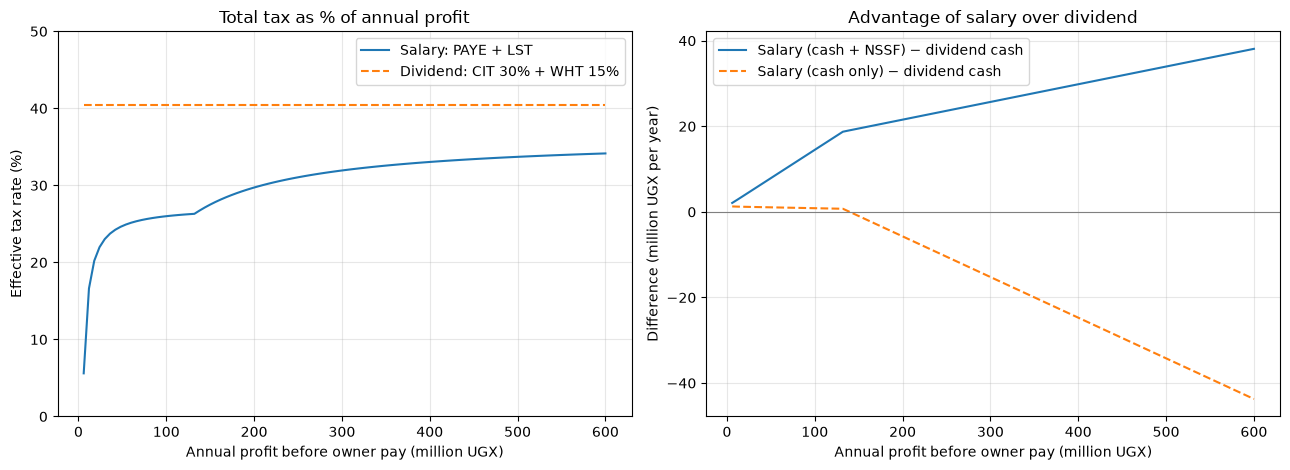

Spendable cash favours dividends from a profit of about UGX 144,000,000


In [18]:
profits = [Money(p) for p in range(6_000_000, 600_000_001, 6_000_000)]   # whole shillings
sweep = planner.sweep(profits, FY)
fig = plot_planner(sweep)
plt.show()

crossover = next((c for c in sweep if c.first.cash_to_owner < c.second.cash_to_owner), None)
print("Spendable cash favours dividends from a profit of about",
      crossover.first.profit if crossover else "(never in this range)")

**Write-up.** The combined dividend route costs a flat **40.5%** (30% CIT, then 15% of the remaining 70%). The
salary route is progressive, so it is far cheaper at low and middle profits: the tax rate rises towards PAYE's 40%
top marginal rate (30% plus the 10% surcharge above 10 million a month) only for very large salaries. In **total
tax**, salary stays cheaper across the whole range. For **spendable cash today** the picture changes, because
15% of the salary budget goes into NSSF (5% employee plus 10% employer). That money belongs to the owner but is
locked until retirement. Above the crossover printed above, a dividend leaves more cash in hand even though it
costs more tax. A real adviser would also weigh: salary must be *reasonable* remuneration to be deductible; dividends
need distributable profits; NSSF savings earn interest and are tax-exempt on withdrawal; and a mix (salary up to a
band, then dividends) is usually optimal. Adding that as a third `Scenario` subclass would need no change to the
planner.

---
## 7. Discussion Q2: where inheritance is justified, and where it was avoided

**Justified:**

* **`Tax` → `PAYE`, `NSSF`, `LocalServiceTax`, `VAT`, `CorporateIncomeTax`, `DividendWithholdingTax`.** This is a
  genuine *is-a* relationship with a single, stable contract (`calculate(ctx) -> TaxResult`). Callers such as the
  pipeline and the planner depend only on the abstraction, the ABC prevents incomplete taxes from being
  instantiated, and the shared `_result()` helper puts rounding in one place.
* **`Scenario` → `SalaryScenario`, `DividendScenario`.** This is the strategy pattern: the planner treats every
  scenario the same way.
* **The exception hierarchy.** `InvalidIncomeError(TaxError, ValueError)` lets callers catch either all tax errors
  or the familiar built-in category.

**Deliberately avoided:**

* **Tax bands and schedules are data, not subclasses.** There is no `PAYE2025` or `NonResidentPAYE` class. A new
  Finance Act means adding a `ProgressiveSchedule` with effective dates to `rates.py`, and the registry picks it by
  date. Subclassing per year would multiply classes and duplicate logic.
* **`Money` does not subclass `Decimal`.** Inheriting would expose every `Decimal` operation, including
  `Money * Money` and mixing with floats through some paths. Composition (wrapping a `Decimal`) lets `Money` allow
  only meaningful operations and add currency checks.
* **`PayrollPipeline` composes taxes instead of being a `Tax`.** It produces a `Payslip`, not one tax, and it
  must allow any component to be swapped (an exempt-from-LST employee, a test double).
* **One `TaxContext`, not a subclass per tax.** If `PAYE.calculate` required an `EmploymentContext` subclass,
  overriding `calculate(ctx: TaxContext)` with a narrower parameter type would break substitutability (the
  Liskov principle). Instead each tax validates the fields it needs and raises `InvalidIncomeError` if they are
  missing.
* **`TaxPlanner` composes two scenarios** rather than inheriting from them, so any pair can be compared.

---
## 8. Tests

`tests/test_paye.py` (boundary tests at every band edge, schedule selection), `tests/test_properties.py`
(**hypothesis**: non-negative, monotonic in income, never exceeding income; derandomised for reproducibility),
`tests/test_money.py` and `tests/test_other_taxes.py`.

In [19]:
result = subprocess.run([sys.executable, "-m", "pytest", "tests/test_money.py", "tests/test_paye.py",
                         "tests/test_properties.py", "tests/test_other_taxes.py", "-q", "--color=no"],
                        capture_output=True, text=True)
print(result.stdout[-2000:] or result.stderr[-2000:])

.......................................................                  [100%]



## Summary

* PAYE, NSSF, LST, VAT and CIT are implemented as subclasses of one abstract `Tax`. The rates are dated data,
  checked against URA's current tables (FY 2026/27 resident rates are identical to the brief).
* All money is `Decimal`-based `Money` with a single, explicit rounding rule (half-up to the shilling).
* The payroll order is NSSF → LST → PAYE → net pay. Only "LST before PAYE" changes any amount.
* Findings: the FY 2026/27 bands save residents up to 13,750 a month compared with FY 2025/26. LST creates a
  net-pay cliff at band edges. Salary extraction is always lower-tax than dividends, but at high profits dividends
  leave more *cash* because of compulsory NSSF saving.